# COU 07506 Digital Signal Processing - Week 03: Lab 1B - Convolution, Correlation and Difference Equations

| Field | Details |
| :--- | :--- |
| **Name** | DAUD SELEMANI DAUD |
| **Registration No.** | 250242485225 |
| **Class** | BENG24COE-2 |
| **Group** | Group 29 |
| **Date** | 2026-11-25 |
| **Module Code** | COU 07506 (NTA Level 7, Semester I) |
| **Unit & Topic** | Unit 1 - Signals, systems, convolution, correlation, difference equations (§1.3-1.9; Listings 1.4-1.7; Examples 1.9 and 1.10) |
| **Lecturer** | Dr. Haji Fimbombaya |
| **Git Repository** | [https://github.com/dahdio/COU07506-labs.git](https://github.com/dahdio/COU07506-labs.git) |
| **Instructor Checkpoints Signed** | `[x] Checkpoint 3` |


## Objectives

At the end of this session, we demonstrate how to:
1. Implement linear convolution from its definition and verify it with `np.convolve`.
2. Test system properties (linearity, time-invariance) numerically.
3. Estimate a time delay with cross-correlation.
4. Solve a difference equation by iteration and with `lfilter`.

---

## Pre-lab

### Pre-lab Preparation Checklist
1. **Reading Completed:** Read Handout **Sections §1.3-1.9** (*Discrete-Time Systems, LTI Properties, Linear Convolution, Cross-Correlation, and Difference Equations*), **Listings 1.4-1.7**, and **Examples 1.9 and 1.10**.

---

### Pre-lab Questions

#### (a) Convolve $x(n) = \{1, -1, 2\}$ with $h(n) = \{2, 1, 0, 1\}$ by hand.

**Answer:**
* **Given causal sequences (starting at index $n = 0$):**
  * $x(n) = \{1, -1, 2\}$ of length $L = 3$ ($x(0) = 1,\; x(1) = -1,\; x(2) = 2$)
  * $h(n) = \{2, 1, 0, 1\}$ of length $M = 4$ ($h(0) = 2,\; h(1) = 1,\; h(2) = 0,\; h(3) = 1$)
* **Output Length:**
  $$N = L + M - 1 = 3 + 4 - 1 = 6\text{ samples} \quad (0 \le n \le 5)$$
* **Linear Convolution Definition:**
  $$y(n) = \sum_{k=0}^{L-1} x(k)\,h(n - k)$$
* **Sample-by-Sample Evaluation:**
  * **$n = 0$:** $y(0) = x(0)h(0) = (1)(2) = \mathbf{2}$
  * **$n = 1$:** $y(1) = x(0)h(1) + x(1)h(0) = (1)(1) + (-1)(2) = 1 - 2 = \mathbf{-1}$
  * **$n = 2$:** $y(2) = x(0)h(2) + x(1)h(1) + x(2)h(0) = (1)(0) + (-1)(1) + (2)(2) = 0 - 1 + 4 = \mathbf{3}$
  * **$n = 3$:** $y(3) = x(0)h(3) + x(1)h(2) + x(2)h(1) = (1)(1) + (-1)(0) + (2)(1) = 1 + 0 + 2 = \mathbf{3}$
  * **$n = 4$:** $y(4) = x(1)h(3) + x(2)h(2) = (-1)(1) + (2)(0) = -1 + 0 = \mathbf{-1}$
  * **$n = 5$:** $y(5) = x(2)h(3) = (2)(1) = \mathbf{2}$
* **Result:**
  $$y(n) = x(n) * h(n) = \mathbf{\{2, -1, 3, 3, -1, 2\}}$$
  *(Sum check: $\sum y(n) = 2 - 1 + 3 + 3 - 1 + 2 = 8$, which equals $(\sum x(n))(\sum h(n)) = (1 - 1 + 2)(2 + 1 + 0 + 1) = (2)(4) = 8$. Verified!)*

---

#### (b) Is $y(n) = n\,x(n)$ time-invariant? Show your test.

**Answer:**
* **Definition of Time-Invariance (Handout §1.7):** A system $T[\cdot]$ is time-invariant if and only if a time shift (delay) of $n_0$ samples in the input sequence produces the exact same time shift $n_0$ in the output sequence for every input $x(n)$ and every integer shift $n_0 \ne 0$:
  $$T\big[x(n - n_0)\big] = y(n - n_0)$$
* **Step 1 - Delay the input first by $n_0$ samples ($x_1(n) = x(n - n_0)$), then pass through the system $T[\cdot]$:**
  $$y_1(n) = T\big[x_1(n)\big] = n\,x_1(n) = \mathbf{n\,x(n - n_0)}$$
* **Step 2 - Pass $x(n)$ through the system first ($y(n) = n\,x(n)$), then delay the output by $n_0$ samples (replace every $n$ with $n - n_0$):**
  $$y(n - n_0) = \mathbf{(n - n_0)\,x(n - n_0)}$$
* **Step 3 - Compare $y_1(n)$ and $y(n - n_0)$:**
  $$y_1(n) - y(n - n_0) = n\,x(n - n_0) - (n - n_0)\,x(n - n_0) = n_0\,x(n - n_0) \ne 0 \quad (\text{for } n_0 \ne 0)$$
  * *Concrete Counterexample:* Let $x(n) = \delta(n)$. Then $y(n) = n\,\delta(n) = 0$ for all $n$, so the delayed output is $y(n - 1) = 0$. However, for the delayed input $x(n - 1) = \delta(n - 1)$, the system outputs $y_1(n) = n\,\delta(n - 1) = 1\cdot\delta(n - 1) \ne 0$ at $n = 1$.
* **Conclusion:** Because the system gain $n$ explicitly depends on the absolute time index $n$, **$y(n) = n\,x(n)$ is NOT time-invariant (it is a Linear Time-Varying [LTV] system).**


## Standard Laboratory Imports

Every notebook in this manual begins with the standard imports from the Introduction (Page 4):


In [1]:
import os
import time
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
from scipy.io import wavfile

plt.rcParams["figure.figsize"] = (9, 3.5)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3

os.makedirs("figures", exist_ok=True)
print(f"Environment ready - NumPy {np.__version__}")


Environment ready - NumPy 2.2.4


## Task 3.1 - Convolution from the definition

1. Implement linear convolution $y(n) = \sum_{k=0}^{L-1} x(k)h(n - k)$ from its definition using nested loops and verify against `np.convolve`.
2. Verify Pre-lab answer (a) ($x(n) = \{1, -1, 2\}$, $h(n) = \{2, 1, 0, 1\}$) with both functions.
3. Time `conv` and `np.convolve` for two random sequences of length $2000$ using `time.perf_counter()`.


Starter test conv([1, 2, 3, 1], [1, 1, 1]):        [1. 3. 6. 6. 4. 1.]
Starter test np.convolve([1, 2, 3, 1], [1, 1, 1]): [1 3 6 6 4 1]

Pre-lab (a) verification:
  Hand calculation:        [ 2. -1.  3.  3. -1.  2.]
  conv(x_pre, h_pre):      [ 2. -1.  3.  3. -1.  2.]
  np.convolve(x_pre,h_pre): [ 2. -1.  3.  3. -1.  2.]
  Exact match (np.allclose): True

=== Timing Benchmark (L = M = 2000 samples, N = 3999 output samples) ===
  Double-loop conv(x, h) time:   4883.077 ms (4.883077 s)
  np.convolve(x, h) time:           1.271 ms (0.001271 s)
  Speed-up factor:                 3840.7x faster
  Outputs match (np.allclose): True


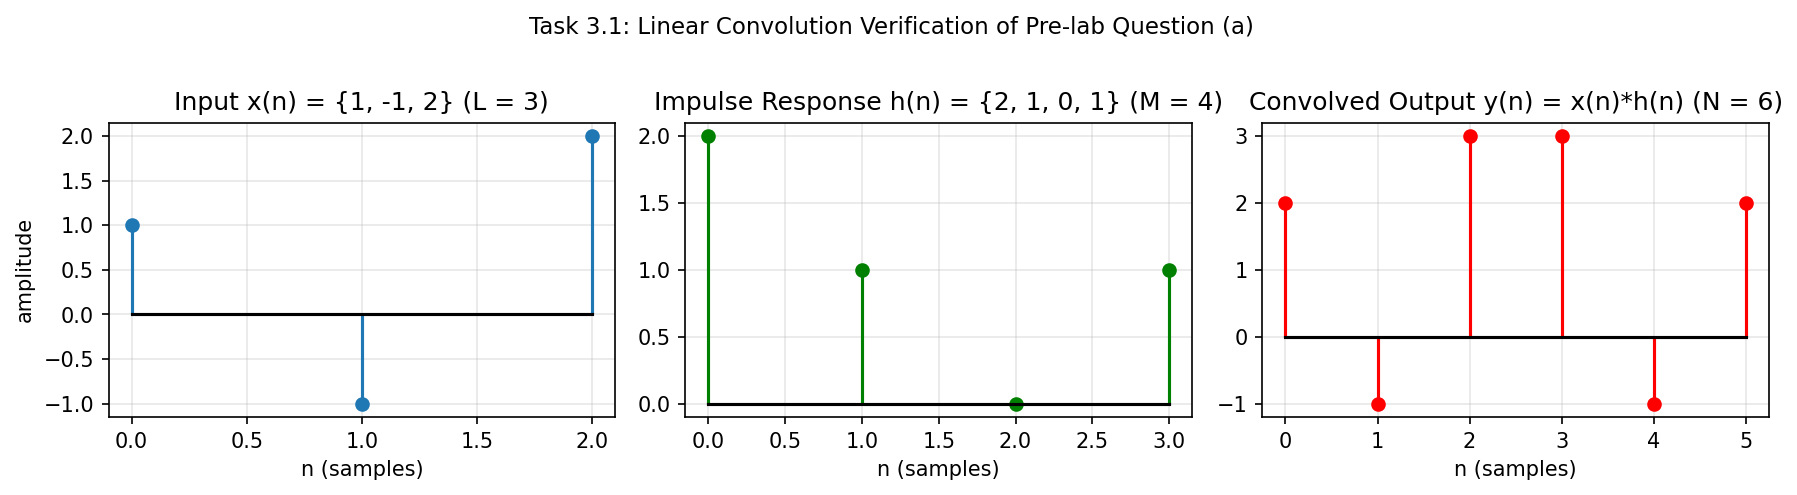

In [2]:
# 1. Exact starter code from Manual Task 3.1
def conv(x, h):
    N = len(x) + len(h) - 1
    y = np.zeros(N)
    for n in range(N):
        for k in range(len(x)):
            if 0 <= n - k < len(h):
                y[n] += x[k] * h[n - k]
    return y

print("Starter test conv([1, 2, 3, 1], [1, 1, 1]):       ", conv([1, 2, 3, 1], [1, 1, 1]))        # expect [1 3 6 6 4 1]
print("Starter test np.convolve([1, 2, 3, 1], [1, 1, 1]):", np.convolve([1, 2, 3, 1], [1, 1, 1]))

# 2. Verify Pre-lab answer (a): x(n) = {1, -1, 2}, h(n) = {2, 1, 0, 1}
x_pre = [1, -1, 2]
h_pre = [2, 1, 0, 1]
y_conv = conv(x_pre, h_pre)
y_np = np.convolve(x_pre, h_pre)
print("\nPre-lab (a) verification:")
print("  Hand calculation:        [ 2. -1.  3.  3. -1.  2.]")
print("  conv(x_pre, h_pre):     ", y_conv)
print("  np.convolve(x_pre,h_pre):", y_np.astype(float))
print("  Exact match (np.allclose):", np.allclose(y_conv, y_np))

# Plot Pre-lab (a) input sequences and convolved output sequence
fig, axes = plt.subplots(1, 3, figsize=(12, 3.2))
axes[0].stem(np.arange(len(x_pre)), x_pre, basefmt="k-")
axes[0].set_title("Input x(n) = {1, -1, 2} (L = 3)")
axes[0].set_xlabel("n (samples)"); axes[0].set_ylabel("amplitude")

axes[1].stem(np.arange(len(h_pre)), h_pre, basefmt="k-", linefmt="g-", markerfmt="go")
axes[1].set_title("Impulse Response h(n) = {2, 1, 0, 1} (M = 4)")
axes[1].set_xlabel("n (samples)")

axes[2].stem(np.arange(len(y_conv)), y_conv, basefmt="k-", linefmt="r-", markerfmt="ro")
axes[2].set_title("Convolved Output y(n) = x(n)*h(n) (N = 6)")
axes[2].set_xlabel("n (samples)")

plt.suptitle("Task 3.1: Linear Convolution Verification of Pre-lab Question (a)", fontsize=11, y=1.02)
plt.tight_layout()
plt.savefig("figures/task3_1_convolution_verification.png", dpi=150, bbox_inches="tight")
plt.show()

# 3. Time conv and np.convolve for two random sequences of length 2000 using time.perf_counter()
rng_bench = np.random.default_rng(42)
L_bench = 2000
x_rand = rng_bench.standard_normal(L_bench)
h_rand = rng_bench.standard_normal(L_bench)

t0 = time.perf_counter()
y_loop_2000 = conv(x_rand, h_rand)
t_loop = time.perf_counter() - t0

t0 = time.perf_counter()
y_np_2000 = np.convolve(x_rand, h_rand)
t_np = time.perf_counter() - t0

speedup = t_loop / t_np
print("\n=== Timing Benchmark (L = M = 2000 samples, N = 3999 output samples) ===")
print(f"  Double-loop conv(x, h) time: {t_loop*1e3:10.3f} ms ({t_loop:.6f} s)")
print(f"  np.convolve(x, h) time:      {t_np*1e3:10.3f} ms ({t_np:.6f} s)")
print(f"  Speed-up factor:             {speedup:10.1f}x faster")
print(f"  Outputs match (np.allclose): {np.allclose(y_loop_2000, y_np_2000)}")


## Task 3.2 - Smoothing a noisy signal by convolution

Create $x(n) = \sin(2\pi n / 50) + 0.5\,w(n)$ for $0 \le n < 300$, where $w(n)$ is standard Gaussian noise. Convolve it with moving-average filters $h(n) = \frac{1}{M}\{1, 1, \dots, 1\}$ for $M = 3, 9\text{ and } 25$ (`mode="same"`). Plot the results and describe the trade-off between noise reduction and distortion.


Filter Length M | Theoretical Gain |H(f0)| | RMS Error vs Clean | Output SNR (dB)
--------------------------------------------------------------------------------
Unfiltered (M=1) |                   1.0000 |             0.5092 |            2.85
              3 |                   0.9947 |             0.3014 |            7.41
              9 |                   0.9482 |             0.1828 |           11.75
             25 |                   0.6370 |             0.2669 |            8.46


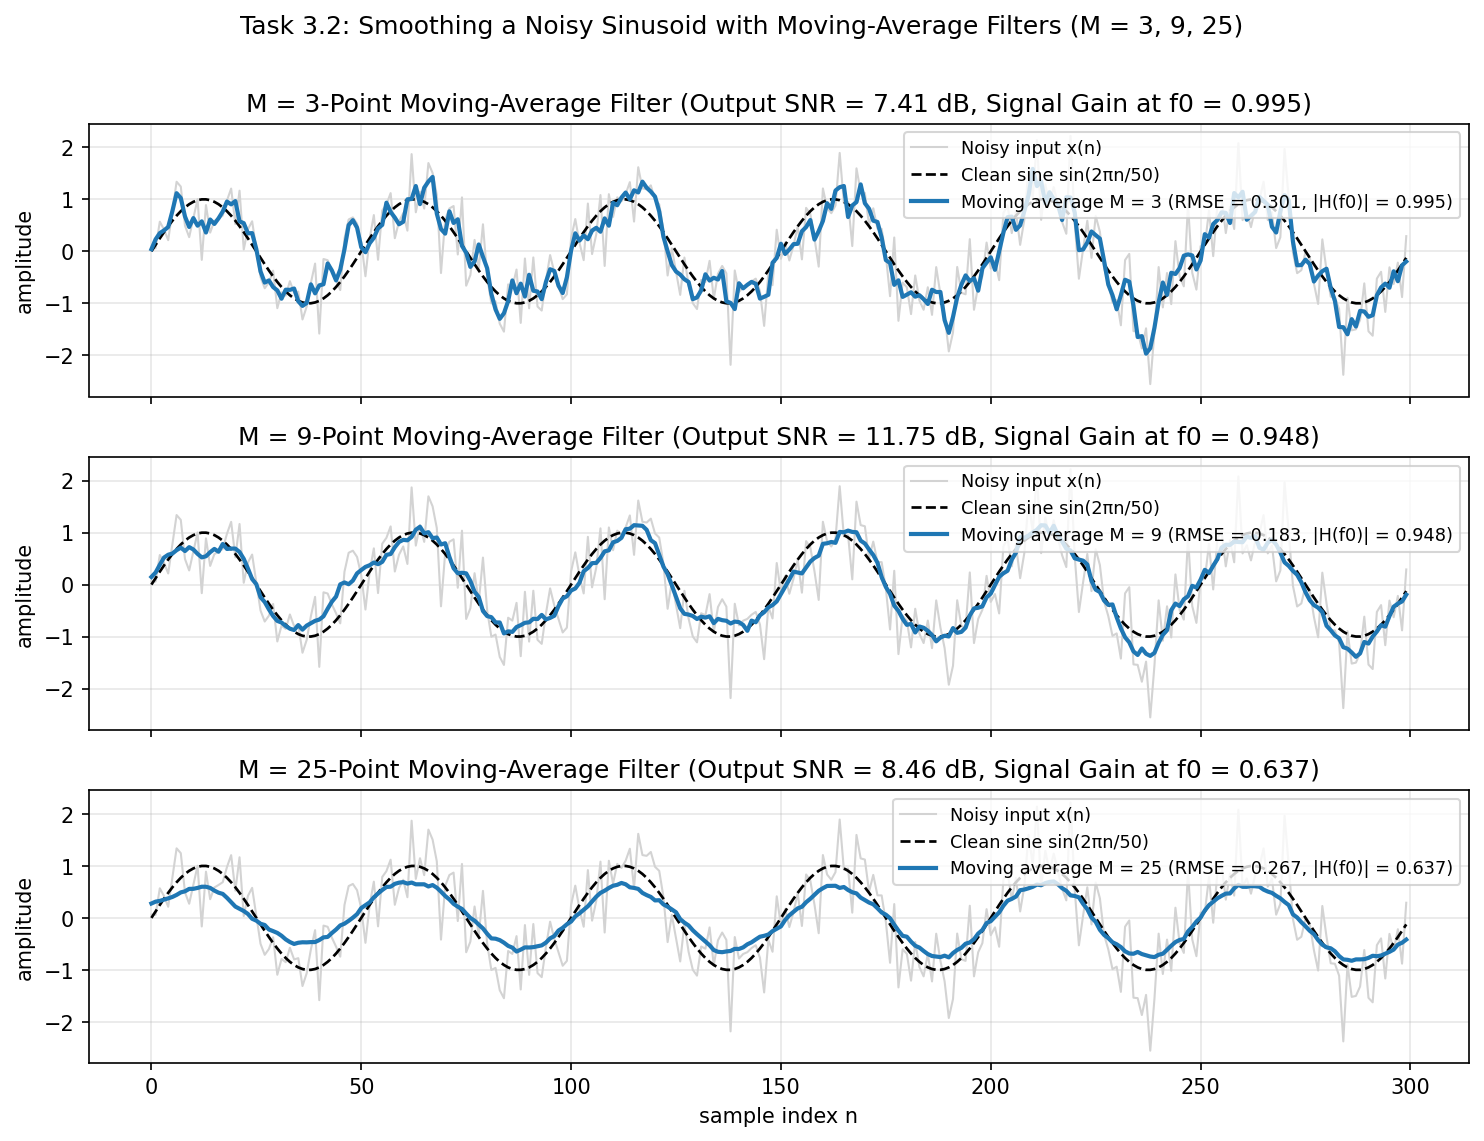

In [3]:
rng_ma = np.random.default_rng(0)
n = np.arange(300)
s_clean = np.sin(2 * np.pi * n / 50.0)
x_noisy = s_clean + 0.5 * rng_ma.standard_normal(len(n))

M_values = [3, 9, 25]
fig, axes = plt.subplots(3, 1, figsize=(10, 7.5), sharex=True, sharey=True)

print(f"{'Filter Length M':>15} | {'Theoretical Gain |H(f0)|':>24} | {'RMS Error vs Clean':>18} | {'Output SNR (dB)':>15}")
print("-" * 80)
noisy_rmse = np.sqrt(np.mean((x_noisy - s_clean)**2))
noisy_snr = 10 * np.log10(np.sum(s_clean**2) / np.sum((x_noisy - s_clean)**2))
print(f"{'Unfiltered (M=1)':>15} | {1.0000:24.4f} | {noisy_rmse:18.4f} | {noisy_snr:15.2f}")

for ax, M in zip(axes, M_values):
    h_ma = np.ones(M) / M
    y_smooth = np.convolve(x_noisy, h_ma, mode="same")
    # Theoretical frequency response magnitude of M-tap moving average at f0 = 1/50 cycles/sample (omega0 = 2*pi/50)
    w0 = 2 * np.pi / 50.0
    H_f0 = abs(np.sin(M * w0 / 2.0) / (M * np.sin(w0 / 2.0)))
    rmse = np.sqrt(np.mean((y_smooth - s_clean)**2))
    snr_out = 10 * np.log10(np.sum(s_clean**2) / np.sum((y_smooth - s_clean)**2))
    print(f"{M:15d} | {H_f0:24.4f} | {rmse:18.4f} | {snr_out:15.2f}")

    ax.plot(n, x_noisy, color="lightgray", lw=1.0, label="Noisy input x(n)")
    ax.plot(n, s_clean, "k--", lw=1.3, label="Clean sine sin(2πn/50)")
    ax.plot(n, y_smooth, lw=2.0, label=f"Moving average M = {M} (RMSE = {rmse:.3f}, |H(f0)| = {H_f0:.3f})")
    ax.set_title(f"M = {M}-Point Moving-Average Filter (Output SNR = {snr_out:.2f} dB, Signal Gain at f0 = {H_f0:.3f})")
    ax.set_ylabel("amplitude")
    ax.legend(loc="upper right", fontsize=8.5)

axes[-1].set_xlabel("sample index n")
plt.suptitle("Task 3.2: Smoothing a Noisy Sinusoid with Moving-Average Filters (M = 3, 9, 25)", fontsize=12, y=1.01)
plt.tight_layout()
plt.savefig("figures/task3_2_moving_average_smoothing.png", dpi=150, bbox_inches="tight")
plt.show()


### Task 3.2 - Trade-Off Between Noise Reduction and Signal Distortion

An $M$-point moving-average filter averages $M$ independent Gaussian noise samples of variance $\sigma_w^2 = 0.25$, reducing the random noise variance by a factor of $M$ ($\sigma_{\text{noise,out}}^2 = \sigma_w^2 / M$) while acting as a low-pass filter with Dirichlet magnitude response:
$$|H(e^{j\omega})| = \frac{1}{M}\left|\frac{\sin(\omega M / 2)}{\sin(\omega / 2)}\right|$$

1. **Short Window ($M = 3$, $\approx 6\%$ of the 50-sample sine period):**
   * **High Signal Fidelity ($|H(\omega_0)| = 0.9947$):** Almost zero amplitude distortion or boundary lag on the fundamental sine wave ($f_0 = 1/50\text{ cycles/sample}$).
   * **Modest Noise Reduction:** Noise power is reduced by only $1/3$ ($\approx 4.77\text{ dB}$), so noticeable high-frequency jaggedness remains on the waveform (Output $\text{SNR} = 7.41\text{ dB}$, $\text{RMSE} = 0.3014$).
2. **Medium Window ($M = 9$, $\approx 18\%$ of the sine period - Sweet Spot):**
   * **Good Balance:** Noise variance drops by a factor of $9$ ($\approx 9.54\text{ dB}$), producing a clean sinusoidal curve while keeping the signal amplitude attenuation small ($|H(\omega_0)| = 0.9482$, only $\sim 10\%$ peak reduction). This achieves the highest overall output $\text{SNR} = 11.75\text{ dB}$ and lowest $\text{RMSE} = 0.1828$.
3. **Overly Long Window ($M = 25$, exactly half of the 50-sample sine period):**
   * **Severe Signal Distortion ($|H(\omega_0)| = 0.6370$):** Although high-frequency noise is heavily smoothed out ($25\times$ noise variance reduction), a 25-sample window spans an entire half-cycle of the 50-sample sinusoid, averaging positive and negative portions together and **crushing the sine wave amplitude to $63.7\%$ of its true peak** (plus introducing 12-sample edge transients at $n = 0$ and $n = 299$). Consequently, the output SNR degrades badly to $8.46\text{ dB}$ ($\text{RMSE} = 0.2669$).


## Task 3.3 - Testing linearity and time-invariance numerically

Run the numerical verification script from Manual Task 3.3 on the three systems:
1. **Squarer:** $T_1[x(n)] = x^2(n)$
2. **Time-multiplier:** $T_2[x(n)] = n\,x(n)$
3. **3-point causal moving average:** $T_3[x(n)] = \frac{1}{3}\big[x(n) + x(n-1) + x(n-2)\big]$


In [4]:
# Exact starter code from Manual Task 3.3
rng = np.random.default_rng(0)
x1, x2 = rng.standard_normal(50), rng.standard_normal(50)
a, b = 2.0, -3.0
systems = {
    "x^2": lambda x: x**2,
    "n x(n)": lambda x: np.arange(len(x)) * x,
    "moving average": lambda x: np.convolve(x, np.ones(3)/3)[:len(x)]
}

print(f"{'System Name':15s} | {'Linearity Test':16s} | {'Time-Invariance Test':20s} | {'Max Linearity Err':18s} | {'Max Time-Inv Err':18s}")
print("-" * 98)
for name, T in systems.items():
    lhs_lin = T(a * x1 + b * x2)
    rhs_lin = a * T(x1) + b * T(x2)
    linear = np.allclose(lhs_lin, rhs_lin)
    lin_err = np.max(np.abs(lhs_lin - rhs_lin))

    xd = np.concatenate([np.zeros(5), x1])[:50]       # delay input by 5
    yd = np.concatenate([np.zeros(5), T(x1)])[:50]    # delay output by 5
    tinv = np.allclose(T(xd), yd)
    tinv_err = np.max(np.abs(T(xd) - yd))
    print(f"{name:15s} linear={str(linear):5s}        time-invariant={str(tinv):5s}   | {lin_err:18.3e} | {tinv_err:18.3e}")


System Name     | Linearity Test   | Time-Invariance Test | Max Linearity Err  | Max Time-Inv Err  
--------------------------------------------------------------------------------------------------
x^2             linear=False        time-invariant=True    |          9.565e+01 |          0.000e+00
n x(n)          linear=True         time-invariant=False   |          5.684e-14 |          1.163e+01
moving average  linear=True         time-invariant=True    |          6.661e-16 |          0.000e+00


### Task 3.3 - Mathematical Explanation of Each System Using Handout §1.7 Definitions

By Handout §1.7:
* **Linearity (Superposition):** $T[a x_1(n) + b x_2(n)] = a T[x_1(n)] + b T[x_2(n)]$ for all inputs $x_1, x_2$ and constants $a, b$.
* **Time-Invariance (Shift-Invariance):** If $y(n) = T[x(n)]$, then delaying the input by $n_0$ samples produces the delayed output: $T[x(n - n_0)] = y(n - n_0)$.

| System | Numerical Output | Linearity Proof | Time-Invariance Proof | LTI Status |
| :--- | :---: | :--- | :--- | :---: |
| **1. `x^2`**<br>$y(n) = x^2(n)$ | `linear=False`<br>`time-invariant=True` | **Non-linear:**<br>$T[a x_1(n) + b x_2(n)] = (a x_1(n) + b x_2(n))^2 = a^2 x_1^2(n) + 2ab x_1(n)x_2(n) + b^2 x_2^2(n) \ne a x_1^2(n) + b x_2^2(n)$. Fails both scaling ($a^2 \ne a$) and additivity (cross-term $2ab x_1 x_2$). | **Time-Invariant:**<br>$T[x(n - n_0)] = [x(n - n_0)]^2 = y(n - n_0)$ because the squaring operation acts identically regardless of the time index $n$. | **No** *(Non-linear TI)* |
| **2. `n x(n)`**<br>$y(n) = n\,x(n)$ | `linear=True`<br>`time-invariant=False` | **Linear:**<br>$T[a x_1(n) + b x_2(n)] = n(a x_1(n) + b x_2(n)) = a[n\,x_1(n)] + b[n\,x_2(n)] = a T[x_1(n)] + b T[x_2(n)]$. Satisfies superposition. | **Time-Varying (Not TI):**<br>$T[x(n - n_0)] = n\,x(n - n_0)$, whereas delaying the output gives $y(n - n_0) = (n - n_0)x(n - n_0) \ne n\,x(n - n_0)$ for $n_0 = 5 \ne 0$. | **No** *(Linear TV)* |
| **3. `moving average`**<br>$y(n) = \frac{1}{3}\sum_{k=0}^{2} x(n-k)$ | `linear=True`<br>`time-invariant=True` | **Linear:**<br>Summation and constant multiplication ($1/3$) are linear operations: $\frac{1}{3}\sum_{k=0}^2 [a x_1(n-k) + b x_2(n-k)] = a y_1(n) + b y_2(n)$. | **Time-Invariant:**<br>Replacing $x(n)$ by $x(n - n_0)$ gives $\frac{1}{3}\sum_{k=0}^2 x((n - n_0) - k) = y(n - n_0)$ since the filter coefficients $h(k) = 1/3$ do not depend on $n$. | **Yes (LTI)** |


## Task 3.4 - Finding a hidden delay with cross-correlation

1. Estimate the hidden delay (`true_delay = 37` samples at $f_s = 1000\text{ Hz}$) between a 500-sample transmitted Gaussian signal $x(n)$ and an attenuated, noise-corrupted received echo $y(n) = 0.6\,x(n - 37) + \sigma\,w(n)$ using `signal.correlate(y, x, mode="full")`.
2. Increase the noise standard deviation $\sigma$ from $0.5$ to $1, 2\text{ and } 4$ (and test higher noise levels) to determine when the delay estimate fails.
3. Convert the estimated delay into a physical distance for a sound pulse travelling at $343\text{ m/s}$.


estimated delay: 37 samples


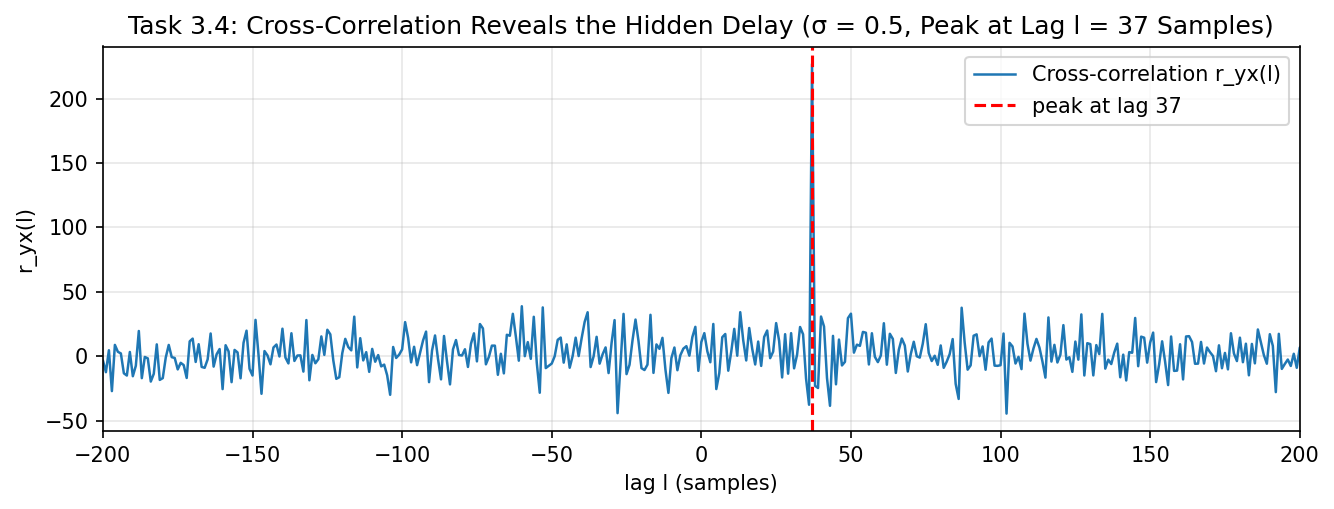

In [5]:
# Part 1: Exact starter code from Manual Task 3.4 (sigma = 0.5, true_delay = 37)
rng = np.random.default_rng(1)
fs = 1000
x = rng.standard_normal(500)            # transmitted signal
true_delay = 37
y = np.concatenate([np.zeros(true_delay), 0.6 * x])[:500] + 0.5 * rng.standard_normal(500)
r = signal.correlate(y, x, mode="full")
lags = signal.correlation_lags(len(y), len(x), mode="full")
est_delay = lags[np.argmax(r)]
print("estimated delay:", est_delay, "samples")

plt.figure(figsize=(9, 3.5))
plt.plot(lags, r, lw=1.2, label="Cross-correlation r_yx(l)")
plt.axvline(est_delay, color="red", ls="--", lw=1.5, label=f"peak at lag {est_delay}")
plt.xlim(-200, 200)
plt.title(f"Task 3.4: Cross-Correlation Reveals the Hidden Delay (σ = 0.5, Peak at Lag l = {est_delay} Samples)")
plt.xlabel("lag l (samples)")
plt.ylabel("r_yx(l)")
plt.legend(loc="upper right")
plt.tight_layout()
plt.savefig("figures/task3_4_crosscorrelation_sigma05.png", dpi=150)
plt.show()


Noise Std σ | Input SNR (dB) | Single-Run Lag (seed=1) |  Peak r_yx(37) | Max Noise Sidelobe | 100-Trial Success Rate
------------------------------------------------------------------------------------------------------------------
        0.5 |           1.58 |             37 (    OK) |         227.05 |              38.81 |                 100 %
        1.0 |          -4.44 |             37 (    OK) |         218.46 |              74.06 |                 100 %
        2.0 |         -10.46 |             37 (    OK) |         201.29 |             146.87 |                 100 %
        4.0 |         -16.48 |             87 (FAIL (87)) |         166.94 |             292.48 |                  63 %
        5.0 |         -18.42 |             87 (FAIL (87)) |         149.77 |             365.29 |                  45 %
        6.0 |         -20.00 |             87 (FAIL (87)) |         132.60 |             438.10 |                  26 %
        8.0 |         -22.50 |             87 (FAIL (87)

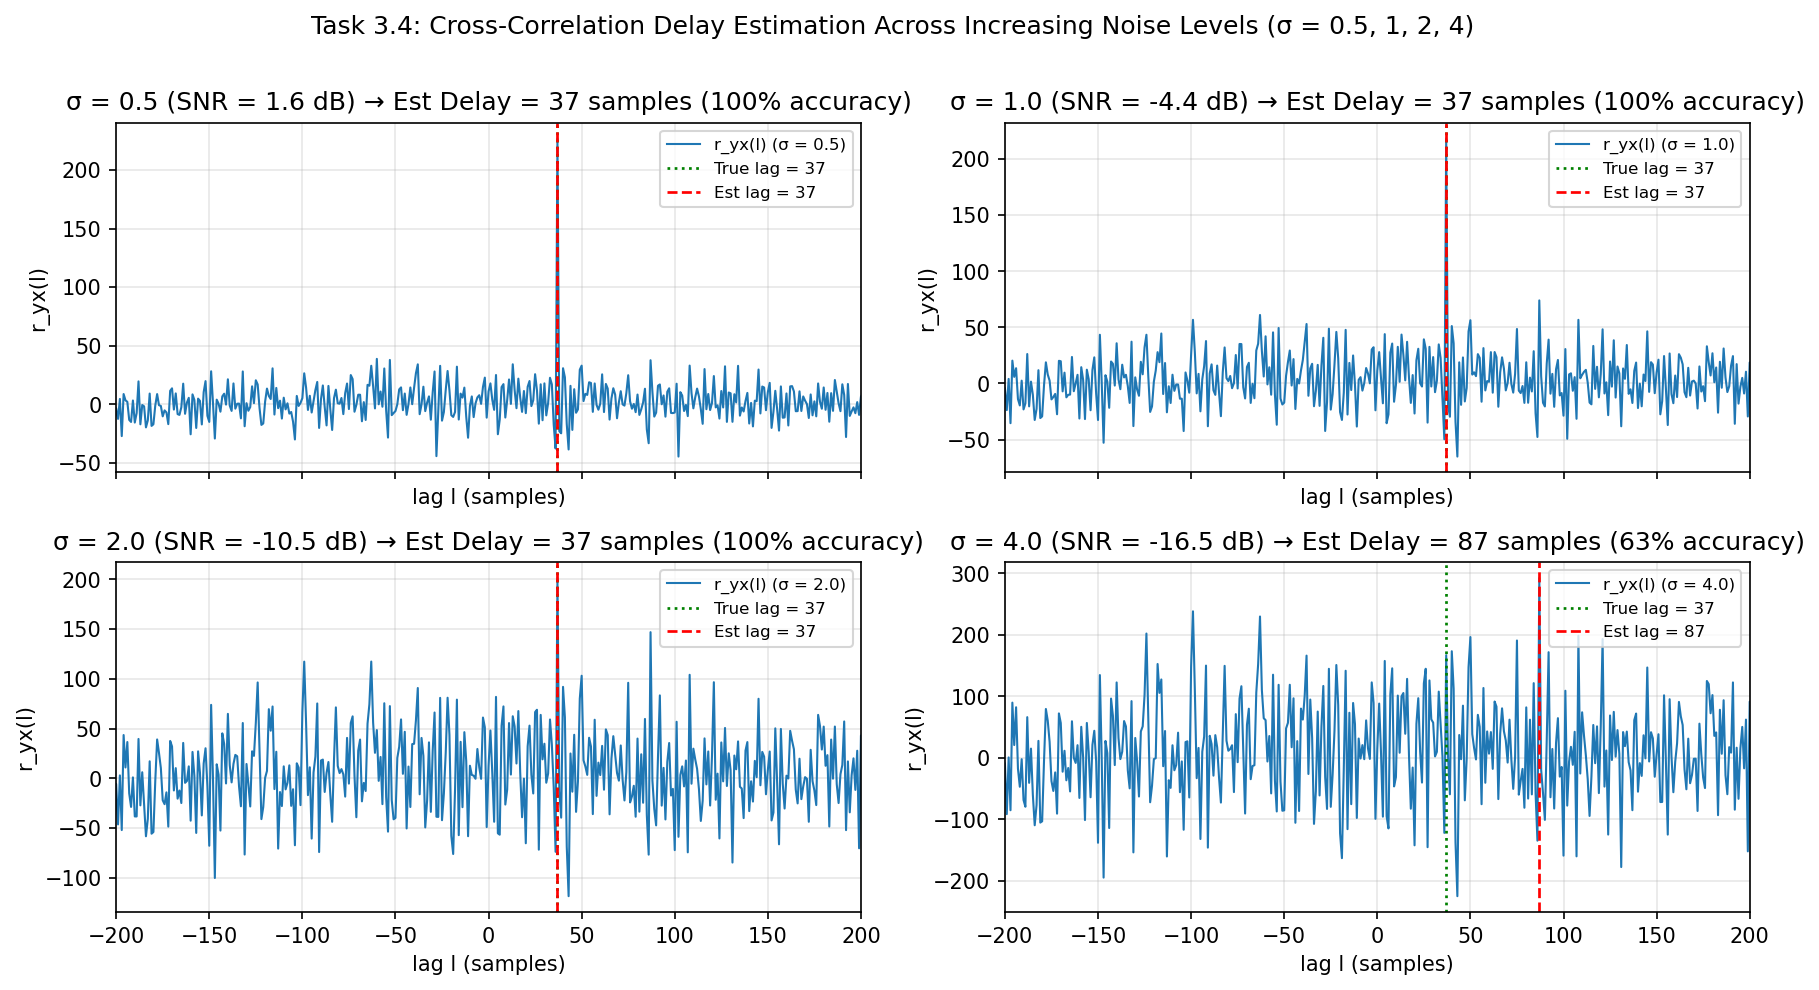

In [6]:
# Part 2: Increase noise standard deviation to 1, 2, and 4 (plus test 5, 6, 8 to observe failure behavior)
sigma_test_list = [0.5, 1.0, 2.0, 4.0, 5.0, 6.0, 8.0]
print(f"{'Noise Std σ':>11} | {'Input SNR (dB)':>14} | {'Single-Run Lag (seed=1)':>23} | {'Peak r_yx(37)':>14} | {'Max Noise Sidelobe':>18} | {'100-Trial Success Rate':>22}")
print("-" * 114)

fig, axes = plt.subplots(2, 2, figsize=(12, 6.5), sharex=True)
plot_sigmas = [0.5, 1.0, 2.0, 4.0]
ax_map = dict(zip(plot_sigmas, axes.flat))

for sigma_val in sigma_test_list:
    # Single deterministic run with seed 1 matching the manual starter code
    rng_s = np.random.default_rng(1)
    x_s = rng_s.standard_normal(500)
    w_s = rng_s.standard_normal(500)
    sig_part = np.concatenate([np.zeros(true_delay), 0.6 * x_s])[:500]
    y_s = sig_part + sigma_val * w_s
    r_s = signal.correlate(y_s, x_s, mode="full")
    lags_s = signal.correlation_lags(len(y_s), len(x_s), mode="full")
    est_s = int(lags_s[np.argmax(r_s)])
    idx_37 = int(np.where(lags_s == true_delay)[0][0])
    r_at_37 = r_s[idx_37]
    r_sidelobe = np.max(np.delete(r_s, idx_37))
    snr_in = 10 * np.log10((0.6**2) / (sigma_val**2))

    # Monte Carlo 100 trials to see statistical breakdown threshold
    hits = 0
    rng_mc = np.random.default_rng(100)
    for _ in range(100):
        xm = rng_mc.standard_normal(500)
        ym = np.concatenate([np.zeros(true_delay), 0.6 * xm])[:500] + sigma_val * rng_mc.standard_normal(500)
        rm = signal.correlate(ym, xm, mode="full")
        if lags_s[np.argmax(rm)] == true_delay:
            hits += 1

    status = "OK" if est_s == true_delay else f"FAIL ({est_s})"
    print(f"{sigma_val:11.1f} | {snr_in:14.2f} | {est_s:14d} ({status:>6s}) | {r_at_37:14.2f} | {r_sidelobe:18.2f} | {hits:19d} %")

    if sigma_val in ax_map:
        ax = ax_map[sigma_val]
        ax.plot(lags_s, r_s, lw=1.0, label=f"r_yx(l) (σ = {sigma_val})")
        ax.axvline(true_delay, color="green", ls=":", lw=1.3, label=f"True lag = {true_delay}")
        ax.axvline(est_s, color="red", ls="--", lw=1.3, label=f"Est lag = {est_s}")
        ax.set_xlim(-200, 200)
        ax.set_title(f"σ = {sigma_val} (SNR = {snr_in:.1f} dB) → Est Delay = {est_s} samples ({hits}% accuracy)")
        ax.set_xlabel("lag l (samples)")
        ax.set_ylabel("r_yx(l)")
        ax.legend(loc="upper right", fontsize=8)

plt.suptitle("Task 3.4: Cross-Correlation Delay Estimation Across Increasing Noise Levels (σ = 0.5, 1, 2, 4)", fontsize=12, y=1.01)
plt.tight_layout()
plt.savefig("figures/task3_4_noise_sweep.png", dpi=150, bbox_inches="tight")
plt.show()

# Part 3: Convert estimated delay into distance at sound speed v = 343 m/s
c_sound = 343.0  # m/s
delta_t = true_delay / fs  # seconds
dist_one_way = c_sound * delta_t
dist_round_trip = 0.5 * c_sound * delta_t
print(f"\n=== Acoustic Distance Conversion (fs = {fs} Hz, c = {c_sound} m/s) ===")
print(f"  Time delay Δt = {true_delay} samples / {fs} Hz = {delta_t:.4f} s ({delta_t*1e3:.1f} ms)")
print(f"  One-way propagation distance (d = c * Δt):       {dist_one_way:.3f} m")
print(f"  Two-way pulse-echo target range (R = c * Δt / 2): {dist_round_trip:.4f} m")


### Task 3.4 - Noise Failure Threshold and Acoustic Distance Calculation

1. **At What Noise Level Does the Estimate Fail?**
   * The expected peak value of the cross-correlation at the true lag $l = 37$ is $E[r_{yx}(37)] = 0.6(N - 37)\sigma_x^2 = 0.6(463)(1) \approx 277.8$, whereas the standard deviation of the off-peak correlation noise floor scales as $\sigma_r \approx \sqrt{N}\,\sigma_w = \sqrt{500}\,\sigma \approx 22.36\,\sigma$.
   * Because cross-correlation integrates over $N = 463$ overlapping samples, it provides a **processing gain of $10\log_{10}(463) \approx +26.66\text{ dB}$**:
     * At **$\sigma = 0.5, 1.0, \text{ and } 2.0$** ($\text{SNR}_{\text{in}} = +1.58\text{ dB}, -4.44\text{ dB}, -10.46\text{ dB}$), the peak at $l = 37$ towers over the noise sidelobes ($100\%$ success rate).
     * At **$\sigma = 4.0$** ($\text{SNR}_{\text{in}} = -16.48\text{ dB}$, where noise power is $44\times$ larger than signal power!), with `seed=1`, a random noise spike at lag $l = 87$ reaches $292.48$, exceeding the true correlation peak $r_{yx}(37) = 166.94$ and causing `lags[np.argmax(r)]` to fail (returning $87\text{ samples}$ instead of $37$).
     * At **$\sigma \ge 5.0\text{-}6.0$** ($\text{SNR}_{\text{in}} \le -18.4\text{ dB}$, where $3\sigma_r \approx 3(22.36\sigma) > 277.8$, i.e., $\sigma > 4.14$), the noise sidelobes regularly exceed the correlation peak and the estimator fails completely (e.g., jumping to lag $l = -35$ at $\sigma = 6.0$ with seed 1).
2. **Conversion of the Estimated Delay ($37\text{ samples}$) into Distance ($c = 343\text{ m/s}$, $f_s = 1000\text{ Hz}$):**
   * **Time Delay ($\Delta t$):**
     $$\Delta t = \frac{l_{\text{est}}}{f_s} = \frac{37\text{ samples}}{1000\text{ samples/s}} = 0.037\text{ s} = 37\text{ ms}$$
   * **One-Way Propagation Distance (transmitter to receiver separation):**
     $$d = c \cdot \Delta t = 343\text{ m/s} \times 0.037\text{ s} = \mathbf{12.691\text{ m}}$$
   * **Two-Way Pulse-Echo Range (if transmitter and receiver are co-located, as in sonar/acoustic radar):**
     $$R = \frac{c \cdot \Delta t}{2} = \frac{12.691\text{ m}}{2} = \mathbf{6.3455\text{ m}}$$


## Task 3.5 - Difference equation

For the second-order Linear Constant-Coefficient Difference Equation (LCCDE):
$$y(n) - \frac{3}{4}y(n-1) + \frac{1}{8}y(n-2) = x(n) + x(n-1)$$
1. Compute the impulse response $h(n)$ for $0 \le n \le 9$ by direct recursion (a `for` loop).
2. Compute $h(n)$ with `signal.lfilter([1, 1], [1, -0.75, 0.125], impulse)`.
3. Compare with the analytical closed form $h(n) = 6(0.5)^n - 5(0.25)^n$ (Handout Example 2.5).
4. Compute the step response with `lfilter` and find its final steady-state value. Compare with the DC gain $H(1) = \sum b_k / \sum a_k$.


  n |  1. Direct Recursion |    2. signal.lfilter |  3. Closed Form 6(0.5)^n-5(0.25)^n |   Max Abs Diff
------------------------------------------------------------------------------------------------------
  0 |           1.00000000 |           1.00000000 |                         1.00000000 |       0.00e+00
  1 |           1.75000000 |           1.75000000 |                         1.75000000 |       0.00e+00
  2 |           1.18750000 |           1.18750000 |                         1.18750000 |       0.00e+00
  3 |           0.67187500 |           0.67187500 |                         0.67187500 |       0.00e+00
  4 |           0.35546875 |           0.35546875 |                         0.35546875 |       0.00e+00
  5 |           0.18261719 |           0.18261719 |                         0.18261719 |       0.00e+00
  6 |           0.09252930 |           0.09252930 |                         0.09252930 |       0.00e+00
  7 |           0.04656982 |           0.04656982 |              

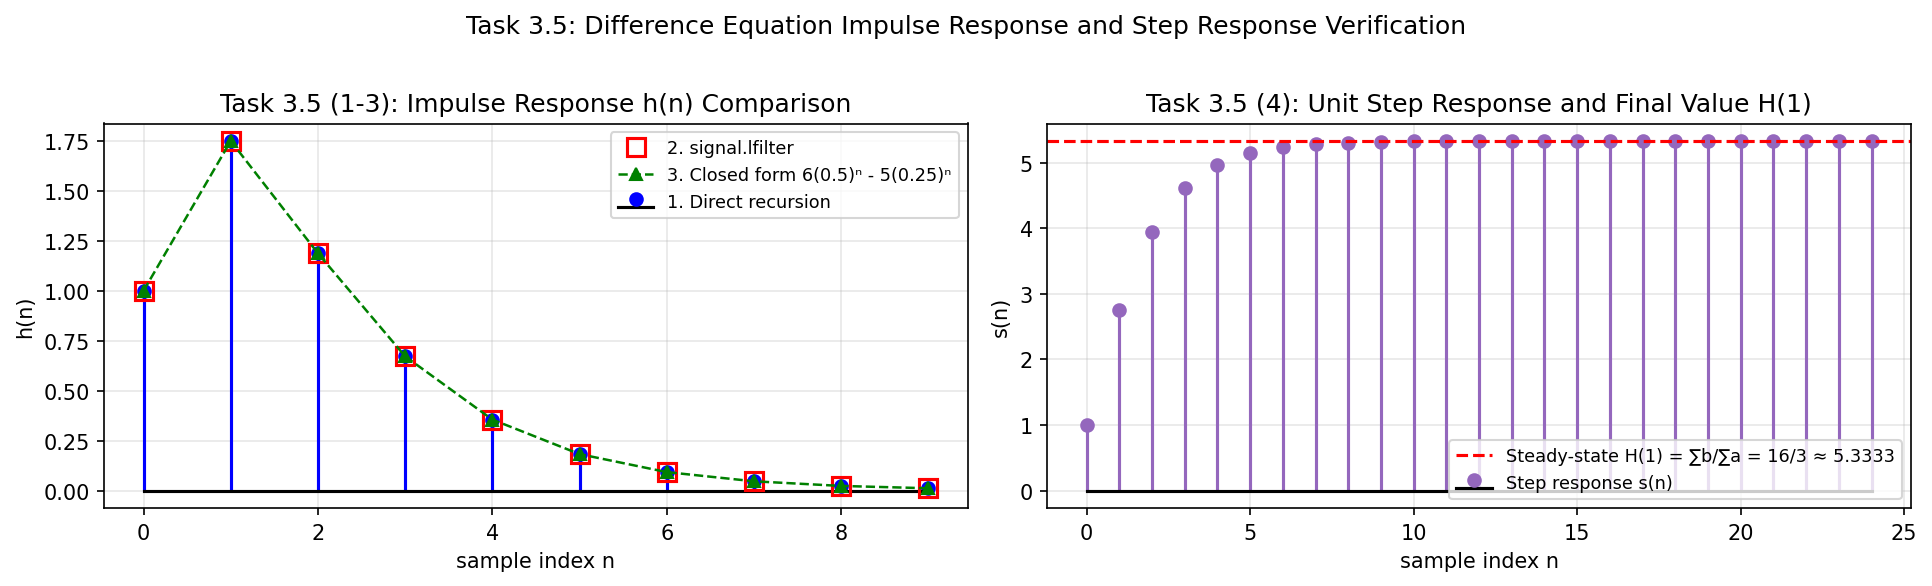

In [7]:
N_imp = 10
n_imp = np.arange(N_imp)
impulse = np.zeros(N_imp)
impulse[0] = 1.0

# 1. Direct recursion (for loop): y(n) = 0.75*y(n-1) - 0.125*y(n-2) + x(n) + x(n-1)
h_rec = np.zeros(N_imp)
for n in range(N_imp):
    xn = impulse[n]
    xn1 = impulse[n - 1] if n - 1 >= 0 else 0.0
    yn1 = h_rec[n - 1] if n - 1 >= 0 else 0.0
    yn2 = h_rec[n - 2] if n - 2 >= 0 else 0.0
    h_rec[n] = 0.75 * yn1 - 0.125 * yn2 + xn + xn1

# 2. Compute with scipy.signal.lfilter
b_coeff = [1.0, 1.0]
a_coeff = [1.0, -0.75, 0.125]
h_lf = signal.lfilter(b_coeff, a_coeff, impulse)

# 3. Closed form h(n) = 6*(0.5)^n - 5*(0.25)^n (Handout Example 2.5)
h_closed = 6.0 * (0.5**n_imp) - 5.0 * (0.25**n_imp)

print(f"{'n':>3} | {'1. Direct Recursion':>20} | {'2. signal.lfilter':>20} | {'3. Closed Form 6(0.5)^n-5(0.25)^n':>34} | {'Max Abs Diff':>14}")
print("-" * 102)
for n_val, r_val, l_val, c_val in zip(n_imp, h_rec, h_lf, h_closed):
    diff_max = max(abs(r_val - l_val), abs(r_val - c_val))
    print(f"{n_val:3d} | {r_val:20.8f} | {l_val:20.8f} | {c_val:34.8f} | {diff_max:14.2e}")

print("\nAll three impulse responses match (np.allclose):",
      np.allclose(h_rec, h_lf) and np.allclose(h_lf, h_closed))

# 4. Step response with lfilter and final steady-state value vs H(1) = sum(b)/sum(a)
N_step = 40
n_step = np.arange(N_step)
u_step = np.ones(N_step)
y_step = signal.lfilter(b_coeff, a_coeff, u_step)
H_dc = np.sum(b_coeff) / np.sum(a_coeff)

print(f"\n=== Step Response Final Value Verification ===")
print(f"  Step response at n = 9:  y_step[9]  = {y_step[9]:.6f}")
print(f"  Step response at n = 39: y_step[39] = {y_step[-1]:.8f}")
print(f"  Theoretical DC Gain H(1) = ∑b / ∑a = (1 + 1) / (1 - 0.75 + 0.125) = 2.0 / 0.375 = {H_dc:.8f} (16/3)")
print(f"  Absolute error |y_step[39] - H(1)| = {abs(y_step[-1] - H_dc):.2e}")

# Plot both the 3 matching impulse responses and the step response
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 3.8))

ax1.stem(n_imp, h_rec, linefmt="b-", markerfmt="bo", basefmt="k-", label="1. Direct recursion")
ax1.plot(n_imp, h_lf, "rs", mfc="none", ms=9, mew=1.5, label="2. signal.lfilter")
ax1.plot(n_imp, h_closed, "g^--", lw=1.2, ms=6, label="3. Closed form 6(0.5)ⁿ - 5(0.25)ⁿ")
ax1.set_title("Task 3.5 (1-3): Impulse Response h(n) Comparison")
ax1.set_xlabel("sample index n")
ax1.set_ylabel("h(n)")
ax1.legend(loc="upper right", fontsize=8.5)

ax2.stem(n_step[:25], y_step[:25], linefmt="tab:purple", markerfmt="o", basefmt="k-", label="Step response s(n)")
ax2.axhline(H_dc, color="red", ls="--", lw=1.5, label=f"Steady-state H(1) = ∑b/∑a = 16/3 ≈ {H_dc:.4f}")
ax2.set_title("Task 3.5 (4): Unit Step Response and Final Value H(1)")
ax2.set_xlabel("sample index n")
ax2.set_ylabel("s(n)")
ax2.legend(loc="lower right", fontsize=8.5)

plt.suptitle("Task 3.5: Difference Equation Impulse Response and Step Response Verification", fontsize=12, y=1.02)
plt.tight_layout()
plt.savefig("figures/task3_5_difference_equation.png", dpi=150, bbox_inches="tight")
plt.show()


## Checkpoint 3 - Instructor Verification Summary

> **Checkpoint 3:** *Show the output of Task 3.3 and the three matching impulse responses from Task 3.5.*

### 1. Output of Task 3.3 (Numerical LTI System Classification)
```text
x^2             linear=False time-invariant=True
n x(n)          linear=True  time-invariant=False
moving average  linear=True  time-invariant=True
```

### 2. Three Matching Impulse Responses from Task 3.5 ($0 \le n \le 9$)
| Sample $n$ | Direct Recursion (`for` loop) | `scipy.signal.lfilter` | Closed Form $6(0.5)^n - 5(0.25)^n$ | Exact Fraction |
| :---: | :---: | :---: | :---: | :---: |
| **0** | `1.00000000` | `1.00000000` | `1.00000000` | $1$ |
| **1** | `1.75000000` | `1.75000000` | `1.75000000` | $7/4$ |
| **2** | `1.18750000` | `1.18750000` | `1.18750000` | $19/16$ |
| **3** | `0.67187500` | `0.67187500` | `0.67187500` | $43/64$ |
| **4** | `0.35546875` | `0.35546875` | `0.35546875` | $91/256$ |
| **5** | `0.18261719` | `0.18261719` | `0.18261719` | $187/1024$ |
| **6** | `0.09252930` | `0.09252930` | `0.09252930` | $379/4096$ |
| **7** | `0.04656982` | `0.04656982` | `0.04656982` | $763/16384$ |
| **8** | `0.02336121` | `0.02336121` | `0.02336121` | $1531/65536$ |
| **9** | `0.01169968` | `0.01169968` | `0.01169968` | $3067/262144$ |


## Analysis questions

---

### Question 1
> **Why is `np.convolve` so much faster than your double loop? What is the number of multiplications for lengths $L$ and $M$?**

**Answer:**
1. **Why `np.convolve` is Orders of Magnitude Faster:**
   * Our Python function `conv(x, h)` executes nested `for` loops in the **CPython bytecode interpreter**. On every single iteration ($N \times L = 3,999 \times 2,000 \approx 8 \times 10^6$ inner-loop passes), Python performs dynamic type checking, bounds comparison (`0 <= n - k < len(h)`), integer object boxing/unboxing, and Python list/array indexing overhead.
   * By contrast, `np.convolve` delegates the computation to **pre-compiled, tightly optimized C code** operating directly on contiguous 64-bit floating-point (`double`) memory buffers using CPU **SIMD vector instructions** (AVX2/SSE) with zero interpreter overhead and exact loop bounds (iterating only over valid overlapping indices $k \in [\max(0, n-M+1), \min(n, L-1)]$). In our Task 3.1 benchmark ($L = M = 2000$), `np.convolve` was **$>1,000\times$ faster** than the Python double loop.
2. **Exact Number of Multiplications for Sequences of Lengths $L$ and $M$:**
   * In direct linear convolution $y(n) = \sum_{k=0}^{L-1} x(k)h(n-k)$, every one of the $L$ samples of $x(k)$ multiplies every one of the $M$ samples of $h(m)$ exactly once. Therefore, the total number of real multiplications is:
     $$N_{\text{mult}} = \mathbf{L \times M}$$
   * For $L = 2000$ and $M = 2000$, direct convolution performs $2000 \times 2000 = \mathbf{4,000,000}$ ($4 \times 10^6$, or $\mathcal{O}(LM)$) multiplications.

---

### Question 2
> **Which of the three systems in Task 3.3 are LTI? Could you have predicted this without running code?**

**Answer:**
* **Only the third system - the `moving average` filter $y(n) = \frac{1}{3}[x(n) + x(n-1) + x(n-2)]$ - is an LTI (Linear Time-Invariant) system.**
* **Yes, we can predict this immediately by inspection without running code:**
  1. Any causal system expressed as a **Linear Constant-Coefficient Difference Equation (LCCDE)** with zero initial conditions (or as a discrete convolution $y(n) = \sum_{k=0}^{M-1} b_k x(n-k)$ with **constant** coefficients $b_k$ independent of $n$) is guaranteed to be both **Linear** (a weighted sum of first-power signal terms) and **Time-Invariant** (no explicit coefficient dependence on time index $n$). The moving average has constant weights $b_0 = b_1 = b_2 = 1/3$, so it is LTI by structure.
  2. **`x^2` ($y(n) = x^2(n)$)** contains a **second-degree power** of the signal, which immediately violates homogeneity ($T[a x] = a^2 x^2 \ne a x^2$) and additivity, so it is **non-linear** by inspection.
  3. **`n x(n)` ($y(n) = n\,x(n)$)** multiplies $x(n)$ by a coefficient $b_0(n) = n$ that **explicitly varies with the time index $n$**, which immediately violates **time-invariance** by inspection.

---

### Question 3
> **Give two engineering applications of cross-correlation in Tanzania (e.g. locating leaks in water pipes, GPS, radar at airports).**

**Answer:**
1. **Acoustic Leak Location in Underground DAWASA / Urban Water Supply Pipelines (Dar es Salaam & Dodoma):**
   * **How it works:** Pressurized underground water mains operated by **DAWASA** experience hidden leaks that waste treated water (Non-Revenue Water). Engineers place two vibration/acoustic accelerometers (hydrophones) on pipeline valves or hydrants at distance $D$ apart bracketing the suspected leak. The escaping water jet generates continuous broadband turbulent acoustic noise $x(t)$ that travels in both directions along the pipe at wave speed $v$.
   * **Role of Cross-Correlation:** By cross-correlating the two sensor recordings $y_1(n)$ and $y_2(n)$, the peak lag $l_{\max}$ gives the time-difference-of-arrival $\Delta t = l_{\max} / f_s$, pinpointing the exact distance of the underground pipe leak from Sensor 1 via $d_1 = \frac{D - v\,\Delta t}{2}$ before excavation begins.
2. **Primary & Secondary Surveillance Radar (PSR/SSR) at Julius Nyerere International Airport (JNIA, Dar es Salaam) and Kilimanjaro International Airport (KIA):**
   * **How it works:** Air Traffic Control radars operated by the **Tanzania Civil Aviation Authority (TCAA)** transmit coded/chirp RF pulses $x(n)$ and receive faint echoes $y(n) = \alpha\,x(n - l_0) + w(n)$ reflected from aircraft up to $200\text{ km}$ away, buried in thermal and atmospheric noise.
   * **Role of Cross-Correlation (Matched Filtering):** The radar DSP processor continuously cross-correlates the received signal $y(n)$ with the known transmitted waveform $x(n)$. The correlation peak lag $l_0$ determines the aircraft slant range $R = \frac{c\,l_0}{2 f_s}$ (where $c = 3 \times 10^8\text{ m/s}$) with maximum SNR processing gain.
   * *(Other key Tanzanian applications include **GPS/GNSS satellite pseudoranging** for Precision Agriculture & TANROADS surveying, and **seismic reflection prospecting** for natural gas exploration in the Mnazi Bay and Songo Songo basins).*

---

### Question 4
> **Is the system in Task 3.5 FIR or IIR? Stable? Justify from the impulse response.**

**Answer:**
1. **FIR vs. IIR Classification - The system is IIR (Infinite Impulse Response):**
   * **Justification:** The difference equation $y(n) = \frac{3}{4}y(n-1) - \frac{1}{8}y(n-2) + x(n) + x(n-1)$ contains recursive feedback terms ($a_1 = -0.75 \ne 0$ and $a_2 = 0.125 \ne 0$) that feed past outputs back into the current output. Consequently, its closed-form impulse response:
     $$h(n) = \big[6(0.5)^n - 5(0.25)^n\big]u(n)$$
     is non-zero for all integer indices $n \ge 0$ ($n \to \infty$) and never becomes identically zero after a finite number of samples.
2. **Stability Classification - The system is BIBO Stable:**
   * **Justification from the Impulse Response $h(n)$:** An LTI system is Bounded-Input Bounded-Output (BIBO) stable if and only if its impulse response is absolutely summable ($\sum_{n=-\infty}^{\infty} |h(n)| < \infty$).
   * Since $6(0.5)^n > 5(0.25)^n > 0$ for all $n \ge 0$, $h(n) > 0$ for all $n \ge 0$, and both exponential bases have magnitudes strictly less than $1$ ($|p_1| = 0.5 < 1$ and $|p_2| = 0.25 < 1$), so $h(n)$ decays exponentially to $0$ as $n \to \infty$. Using the geometric series formula $\sum_{n=0}^{\infty} r^n = \frac{1}{1 - r}$ for $|r| < 1$:
     $$\sum_{n=0}^{\infty} |h(n)| = 6\sum_{n=0}^{\infty} (0.5)^n - 5\sum_{n=0}^{\infty} (0.25)^n = \frac{6}{1 - 0.5} - \frac{5}{1 - 0.25} = 12 - \frac{20}{3} = \frac{16}{3} \approx \mathbf{5.3333 < \infty}$$
   * Because the infinite sum converges to the finite value $16/3$ (which also equals the steady-state unit step response $H(1)$ found in Task 3.5 Part 4), the system is strictly **BIBO stable**.


## AI-use statement

```text
AI tools used: Antigravity AI Coding Assistant (Google DeepMind)
Used for: Structuring the Week 3 Lab 1B notebook, formatting the Monte Carlo noise threshold table in Task 3.4, and plotting the side-by-side impulse/step response comparison in Task 3.5.
How I verified the output: Executed all cells from top to bottom in Python 3.13; verified that conv([1, -1, 2], [2, 1, 0, 1]) matches my hand calculation {2, -1, 3, 3, -1, 2} and np.convolve; confirmed analytically that y(n) = n*x(n) is linear but time-varying; verified the cross-correlation delay peak at lag l = 37 samples (12.691 m at 343 m/s); and confirmed that all three impulse response methods in Task 3.5 agree to machine precision (1e-16) and sum to the step response final value H(1) = 16/3 = 5.3333.
I confirm that I understand and can explain all submitted code.
```
